In [ ]:
!wget http://www.eecs.umich.edu/courses/eecs442-ahowens/fa20/psets/ps10_data/MPI-Sintel-442.zip

# 检查pytorch是否能够运行

In [1]:
import sys
sys.path.append("/home/aistudio/external-libraries")
import torch
print(torch.__version__)
torch.cuda.is_available()

2.10.0+cu128


True

# EECS 442 PS10: Optical Flow and Epipolar Geometry

**Calvin Tran, cktran**  
December 8, 2021

## Overview

In this problem set, You will implemente the optical flow network (PWN-Net) for estimating dense motion between a pair of images. You will also visualize epipolar lines for a pair of stereo images.

## Starting

Run the following code to import the modules you’ll need.

In [2]:
from glob import glob

import math, os, random
import matplotlib.pyplot as plt
from matplotlib.pyplot import imread  # alternative to scipy.misc.imread
import matplotlib.patches as patches
import numpy as np
import os.path
from os.path import *
import torch
import torch.utils.data as data
from torch.utils.data import DataLoader
from tqdm import tqdm_notebook

We will use GPUs to accelerate our computation in this notebook. Run the following to make sure GPUs are enabled:

In [3]:
if torch.cuda.is_available():
    print('Good to go!')
else:
    print('Please set GPU via Edit -> Notebook Settings.')

Good to go!


In [ ]:
!wget http://www.eecs.umich.edu/courses/eecs442-ahowens/fa20/psets/ps10_data/MPI-Sintel-442.zip
!unzip -q MPI-Sintel-442.zip  # This might take a few minutes.

Define some flow utility functions. You don’t need to understand codes in this part for the problem set.

In [4]:
TAG_CHAR = np.array([202021.25], np.float32)

def readFlow(fn):
    """ Read .flo file in Middlebury format"""
    # Code adapted from:
    # http://stackoverflow.com/questions/28013200/reading-middlebury-flow-files-with-python-bytes-array-numpy

    # WARNING: this will work on little-endian architectures (eg Intel x86) only!
    # print 'fn = %s'%(fn)
    with open(fn, 'rb') as f:
        magic = np.fromfile(f, np.float32, count=1)
        if 202021.25 != magic:
            print('Magic number incorrect. Invalid .flo file')
            return None
        else:
            w = np.fromfile(f, np.int32, count=1)
            h = np.fromfile(f, np.int32, count=1)
            # print 'Reading %d x %d flo file\n' % (w, h)
            data = np.fromfile(f, np.float32, count=2*int(w)*int(h))
            # Reshape data into 3D array (columns, rows, bands)
            # The reshape here is for visualization, the original code is (w,h,2)
            return np.resize(data, (int(h), int(w), 2)) 

def writeFlow(filename, uv, v=None):
    """ Write optical flow to file.
    Expect input flow as shape H,W,2(u,v) if v is None.
    If v is None, uv is assumed to contain both u and v channels,
    stacked in depth.
    Original code by Deqing Sun, adapted from Daniel Scharstein.
    """
    nBands = 2

    if v is None:
        assert(uv.ndim == 3)
        assert(uv.shape[2] == 2)
        u = uv[:,:,0]
        v = uv[:,:,1]
    else:
        u = uv

    assert(u.shape == v.shape)
    height, width = u.shape
    f = open(filename, 'wb')
    # write the header
    f.write(TAG_CHAR)
    np.array(width).astype(np.int32).tofile(f)
    np.array(height).astype(np.int32).tofile(f)
    # arrange into matrix form
    tmp = np.zeros((height, width*nBands))
    tmp[:, np.arange(width)*2] = u
    tmp[:, np.arange(width)*2 + 1] = v
    tmp.astype(np.float32).tofile(f)
    f.close()

# ref: https://github.com/sampepose/flownet2-tf/
# blob/18f87081db44939414fc4a48834f9e0da3e69f4c/src/flowlib.py#L240
def visulize_flow_file(flow_filename, save_dir=None):
    flow_data = readFlow(flow_filename)  # HW2
    #print(flow_data)
    img = flow2img(flow_data)
    plt.imshow(img)
    plt.show()
    if save_dir:
        idx = flow_filename.rfind("/") + 1
        plt.imsave(os.path.join(save_dir, "%s-vis.png" % flow_filename[idx:-4]), img)

def visualize_flow_array(flow_data, plot=True, title=None):
    """
    flow_data: array of shape H,W,2
    """
    img = flow2img(flow_data)
    if plot:
        plt.imshow(img)
        plt.axis('off')
        if title:
            plt.title(title)
        plt.show()
    return img

def flow2img(flow_data):
    """
    convert optical flow into color image
    :param flow_data:
    :return: color image
    """
    # print(flow_data.shape)
    # print(type(flow_data))
    u = flow_data[:, :, 0]
    v = flow_data[:, :, 1]

    UNKNOW_FLOW_THRESHOLD = 1e7
    pr1 = abs(u) > UNKNOW_FLOW_THRESHOLD
    pr2 = abs(v) > UNKNOW_FLOW_THRESHOLD
    idx_unknown = (pr1 | pr2)
    u[idx_unknown] = v[idx_unknown] = 0

    # get max value in each direction
    maxu = -999.
    maxv = -999.
    minu = 999.
    minv = 999.
    maxu = max(maxu, np.max(u))
    maxv = max(maxv, np.max(v))
    minu = min(minu, np.min(u))
    minv = min(minv, np.min(v))

    rad = np.sqrt(u ** 2 + v ** 2)
    maxrad = max(-1, np.max(rad))
    #print(maxrad)
    u = u / maxrad + np.finfo(float).eps
    v = v / maxrad + np.finfo(float).eps

    img = compute_color(u, v)

    idx = np.repeat(idx_unknown[:, :, np.newaxis], 3, axis=2)
    img[idx] = 0

    return np.uint8(img)

def compute_color(u, v):
    """
    compute optical flow color map
    :param u: horizontal optical flow
    :param v: vertical optical flow
    :return:
    """
    height, width = u.shape
    img = np.zeros((height, width, 3))

    NAN_idx = np.isnan(u) | np.isnan(v)
    u[NAN_idx] = v[NAN_idx] = 0

    colorwheel = make_color_wheel()
    ncols = np.size(colorwheel, 0)

    rad = np.sqrt(u ** 2 + v ** 2)

    a = np.arctan2(-v, -u) / np.pi

    fk = (a + 1) / 2 * (ncols - 1) + 1

    k0 = np.floor(fk).astype(int)

    k1 = k0 + 1
    k1[k1 == ncols + 1] = 1
    f = fk - k0

    for i in range(0, np.size(colorwheel, 1)):
        tmp = colorwheel[:, i]
        col0 = tmp[k0 - 1] / 255
        col1 = tmp[k1 - 1] / 255
        col = (1 - f) * col0 + f * col1

        idx = rad <= 1
        col[idx] = 1 - rad[idx] * (1 - col[idx])
        notidx = np.logical_not(idx)

        col[notidx] *= 0.75
        img[:, :, i] = np.uint8(np.floor(255 * col * (1 - NAN_idx)))

    return img

def make_color_wheel():
    """
    Generate color wheel according Middlebury color code
    :return: Color wheel
    """
    RY = 15
    YG = 6
    GC = 4
    CB = 11
    BM = 13
    MR = 6

    ncols = RY + YG + GC + CB + BM + MR

    colorwheel = np.zeros([ncols, 3])

    col = 0

    # RY
    colorwheel[0:RY, 0] = 255
    colorwheel[0:RY, 1] = np.transpose(np.floor(255 * np.arange(0, RY) / RY))
    col += RY

    # YG
    colorwheel[col:col + YG, 0] = 255 - np.transpose(np.floor(255 * np.arange(0, YG) / YG))
    colorwheel[col:col + YG, 1] = 255
    col += YG

    # GC
    colorwheel[col:col + GC, 1] = 255
    colorwheel[col:col + GC, 2] = np.transpose(np.floor(255 * np.arange(0, GC) / GC))
    col += GC

    # CB
    colorwheel[col:col + CB, 1] = 255 - np.transpose(np.floor(255 * np.arange(0, CB) / CB))
    colorwheel[col:col + CB, 2] = 255
    col += CB

    # BM
    colorwheel[col:col + BM, 2] = 255
    colorwheel[col:col + BM, 0] = np.transpose(np.floor(255 * np.arange(0, BM) / BM))
    col += BM

    # MR
    colorwheel[col:col + MR, 2] = 255 - np.transpose(np.floor(255 * np.arange(0, MR) / MR))
    colorwheel[col:col + MR, 0] = 255

    return colorwheel

# fram utils
def read_gen(file_name):
    ext = splitext(file_name)[-1]
    if ext == '.png' or ext == '.jpeg' or ext == '.ppm' or ext == '.jpg':
        im = imread(file_name)
        if im.shape[2] > 3:
            return im[:,:,:3]
        else:
            return im
    elif ext == '.bin' or ext == '.raw':
        return np.load(file_name)
    elif ext == '.flo':
        return readFlow(file_name).astype(np.float32)
    return []

<img src='./opticalflowColorWheel.jpg' width = 300>


# Middlebury Optical Flow Color Code 数学原理

## 1. 光流向量定义

对于图像中每个像素 $(x,y)$，光流向量表示为：

$$
\mathbf{F}(x,y)=
\begin{bmatrix}
u(x,y)\\
v(x,y)
\end{bmatrix}
$$

其中：

- $u(x,y)$：水平方向的运动分量。
- $v(x,y)$：垂直方向的运动分量。

## 2. 计算光流幅度

光流向量的模长：

$$
r(x,y)=\sqrt{u(x,y)^2+v(x,y)^2}
$$

归一化：

$$
r_{\mathrm{norm}}(x,y)
=
\frac{r(x,y)}{r_{\max}+\varepsilon}
$$

其中：

$$
r_{\max}=\max_{x,y}r(x,y)
$$

$\varepsilon$ 是防止除零的小常数。

## 3. 计算光流方向

使用反正切函数计算光流方向角：

$$
\theta(x,y)=\operatorname{atan2}(-v(x,y),-u(x,y))
$$

其取值范围为：

$$
-\pi\leq\theta\leq\pi
$$

将方向角转换为颜色轮上的归一化位置：

$$
f(x,y)=\frac{\theta(x,y)/\pi+1}{2}
$$

因此：

$$
0\leq f(x,y)\leq1
$$

## 4. 将方向映射到 Color Wheel

Middlebury Color Wheel 由六段颜色渐变构成：

| 颜色区间 | 颜色变化 | 采样数量 |
|---|---|---:|
| RY | Red → Yellow | 15 |
| YG | Yellow → Green | 6 |
| GC | Green → Cyan | 4 |
| CB | Cyan → Blue | 11 |
| BM | Blue → Magenta | 13 |
| MR | Magenta → Red | 6 |

总采样数量：

$$
N=15+6+4+11+13+6=55
$$

将方向位置转换为颜色轮索引：

$$
k=f(N-1)
$$

$$
k_0=\lfloor k\rfloor
$$

$$
k_1=(k_0+1)\bmod N
$$

插值系数：

$$
\alpha=k-k_0
$$

设颜色轮中第 $k$ 个颜色为 $C_k$，则：

$$
C_{\mathrm{wheel}}
=
(1-\alpha)C_{k_0}
+
\alpha C_{k_1}
$$

这里的 RGB 颜色分量归一化到 $[0,1]$。

## 5. 根据光流幅度调整颜色

当 $r_{\mathrm{norm}}\leq1$ 时：

$$
C=1-r_{\mathrm{norm}}(1-C_{\mathrm{wheel}})
$$

当 $r_{\mathrm{norm}}>1$ 时：

$$
C=0.75C_{\mathrm{wheel}}
$$

其中 $1$ 表示白色 RGB 向量 $(1,1,1)$。

## 6. 最终映射函数

Middlebury 光流颜色编码可以表示为：

$$
(u,v)\longrightarrow(r,\theta)
$$

$$
(r,\theta)\longrightarrow C_{\mathrm{wheel}}(\theta)
$$

$$
(r,C_{\mathrm{wheel}})\longrightarrow RGB
$$

最终：

$$
\boxed{
C(x,y)=\Phi(u(x,y),v(x,y))
}
$$

其中 $\Phi$ 表示完整的方向映射、颜色轮插值和幅度调整过程。

## 7. 数学量与可视化含义

| 数学量 | 可视化含义 |
|---|---|
| $u$ | 水平运动 |
| $v$ | 垂直运动 |
| $r$ | 运动幅度 |
| $\theta$ | 运动方向 |
| $C_{\mathrm{wheel}}$ | 方向对应的颜色 |
| $C$ | 最终 RGB 颜色 |

**核心结论：**

Middlebury Color Code 使用颜色色相编码光流方向，使用颜色与白

/tmp/ipykernel_1096/2823440680.py:19: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  data = np.fromfile(f, np.float32, count=2*int(w)*int(h))
/tmp/ipykernel_1096/2823440680.py:22: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return np.resize(data, (int(h), int(w), 2))


(436, 1024, 2)


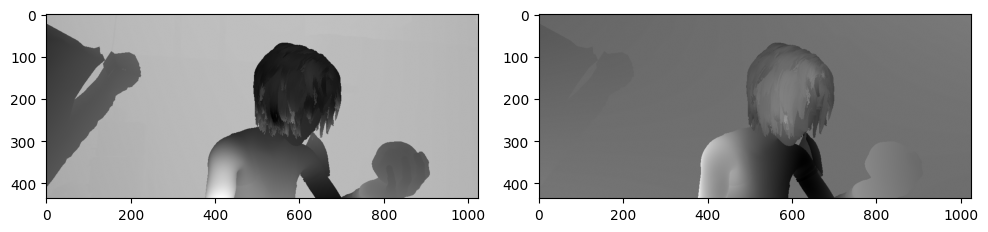

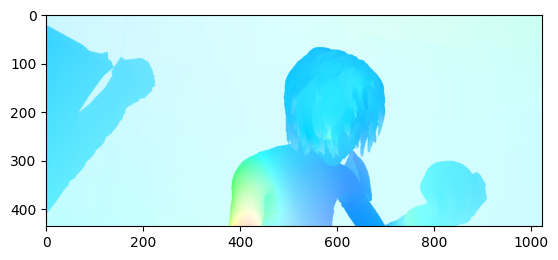

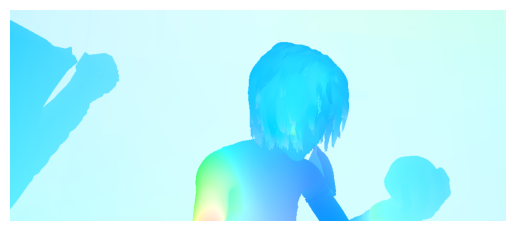

array([[[200, 245, 255],
        [201, 245, 255],
        [201, 245, 255],
        ...,
        [210, 255, 237],
        [210, 255, 237],
        [210, 255, 237]],

       [[200, 245, 255],
        [201, 245, 255],
        [201, 245, 255],
        ...,
        [210, 255, 237],
        [210, 255, 237],
        [210, 255, 237]],

       [[200, 245, 255],
        [201, 245, 255],
        [201, 245, 255],
        ...,
        [210, 255, 237],
        [210, 255, 237],
        [210, 255, 237]],

       ...,

       [[188, 253, 255],
        [188, 253, 255],
        [188, 253, 255],
        ...,
        [205, 251, 255],
        [205, 251, 255],
        [205, 251, 255]],

       [[188, 253, 255],
        [188, 253, 255],
        [188, 253, 255],
        ...,
        [205, 251, 255],
        [205, 251, 255],
        [205, 251, 255]],

       [[191, 254, 255],
        [191, 254, 255],
        [191, 254, 255],
        ...,
        [205, 251, 255],
        [205, 251, 255],
        [205, 251, 255]]

In [8]:
fileFlo = '/home/aistudio/EECS442_Ps10_OpticalFlow/MPI-Sintel-442/training/flow/alley_1/frame_0001.flo'
alley1_1Flow = readFlow(fileFlo)
flo = alley1_1Flow
print(flo.shape)
u = flo[:,:,0]
v = flo[:,:,1]
fig,axes = plt.subplots(1,2,figsize = (10,5))
axes[0].imshow(u,cmap='gray')
axes[1].imshow(v,cmap='gray')
plt.tight_layout()
plt.show()

flowImg = flow2img(flo)
plt.imshow(flowImg)
plt.show()

visualize_flow_array(flo)




Define the data augmentation functions, dataset and dataloader.

In [5]:
class StaticRandomCrop(object):
    def __init__(self, image_size, crop_size):
        self.th, self.tw = crop_size
        h, w = image_size
        self.h1 = random.randint(0, h - self.th)
        self.w1 = random.randint(0, w - self.tw)

    def __call__(self, img):
        return img[self.h1:(self.h1+self.th), self.w1:(self.w1+self.tw), :]

class StaticCenterCrop(object):
    def __init__(self, image_size, crop_size):
        self.th, self.tw = crop_size
        self.h, self.w = image_size

    def __call__(self, img):
        return img[(self.h-self.th)//2:(self.h+self.th)//2, (self.w-self.tw)//2:(self.w+self.tw)//2, :]

class MpiSintel(data.Dataset):
    def __init__(self, crop_size=[384, 512], render_size=[384, 1024], train=False, root='', dstype='clean'):
        flow_root = join(root, 'flow')
        image_root = join(root, dstype)

        self.crop_size = crop_size
        self.render_size = render_size
        self.train = train
        file_list = sorted(glob(join(flow_root, '*/*.flo')))
        # Randomly select out 100 samples for test set
        import random
        random.seed(30)
        random.shuffle(file_list)
        if self.train:
            file_list = file_list[:-100]
        else:
            file_list = file_list[-100:]
        self.flow_list = []
        self.image_list = []

        for file in file_list:
            if 'test' in file:
                # print file
                continue

            fbase = file[len(flow_root)+1:]
            fprefix = fbase[:-8]
            fnum = int(fbase[-8:-4])

            img1 = join(image_root, fprefix + "%04d" % (fnum+0) + '.png')
            img2 = join(image_root, fprefix + "%04d" % (fnum+1) + '.png')

            if not isfile(img1) or not isfile(img2) or not isfile(file):
                continue

            self.image_list += [[img1, img2]]
            self.flow_list += [file]

        self.size = len(self.image_list)

        self.frame_size = read_gen(self.image_list[0][0]).shape

        if (self.render_size[0] < 0) or (self.render_size[1] < 0) or (self.frame_size[0] % 64) or (self.frame_size[1] % 64):
            self.render_size[0] = ((self.frame_size[0]) // 64) * 64
            self.render_size[1] = ((self.frame_size[1]) // 64) * 64

        assert (len(self.image_list) == len(self.flow_list))

    def __getitem__(self, index):
        index = index % self.size

        img1 = read_gen(self.image_list[index][0])
        img2 = read_gen(self.image_list[index][1])

        flow = read_gen(self.flow_list[index])  # H,W,2

        images = [img1, img2]
        image_size = img1.shape[:2]

        if self.train:
            # cropper = StaticCenterCrop(image_size, self.crop_size)
            # print(image_size, self.render_size)
            cropper = StaticRandomCrop(image_size, self.crop_size)
        else:
            # print(image_size, self.render_size)
            cropper = StaticCenterCrop(image_size, self.render_size)
        images = list(map(cropper, images))  # 2,H,W,3
        flow = cropper(flow)
        images = np.array(images).transpose(0, 3, 1, 2)
        flow = flow.transpose(2, 0, 1)  # 2,H,W

        images = torch.from_numpy(images.astype(np.float32)) / 255.
        flow = torch.from_numpy(flow.astype(np.float32))

        return images, flow  # 2,3,H,W and 2,H,W

    def __len__(self):
        return self.size

class MpiSintelClean(MpiSintel):
    def __init__(self, crop_size=[384, 512], render_size=[384, 1024], train=False, root=''):
        super(MpiSintelClean, self).__init__(train=train, root=root, dstype='clean')

In [6]:


train_dataset = MpiSintelClean(crop_size=[384, 512], render_size=[384, 1024], train=True, root='/home/aistudio/EECS442_Ps10_OpticalFlow/MPI-Sintel-442/training')  # Return crops of size 384, 512
val_dataset = MpiSintelClean(crop_size=[384, 512], render_size=[384, 1024], train=False, root='/home/aistudio/EECS442_Ps10_OpticalFlow/MPI-Sintel-442/training')  # Return images of size 384,1024
train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False)

overfit_dataset = torch.utils.data.Subset(val_dataset, [0])
overfit_dataloader = DataLoader(overfit_dataset, batch_size=1, shuffle=False)


In [7]:
imageList = train_dataset.image_list
flowList = train_dataset.flow_list
print(imageList[:10])
print(flowList[:10])

[['/home/aistudio/EECS442_Ps10_OpticalFlow/MPI-Sintel-442/training/clean/market_6/frame_0027.png', '/home/aistudio/EECS442_Ps10_OpticalFlow/MPI-Sintel-442/training/clean/market_6/frame_0028.png'], ['/home/aistudio/EECS442_Ps10_OpticalFlow/MPI-Sintel-442/training/clean/alley_2/frame_0032.png', '/home/aistudio/EECS442_Ps10_OpticalFlow/MPI-Sintel-442/training/clean/alley_2/frame_0033.png'], ['/home/aistudio/EECS442_Ps10_OpticalFlow/MPI-Sintel-442/training/clean/alley_1/frame_0037.png', '/home/aistudio/EECS442_Ps10_OpticalFlow/MPI-Sintel-442/training/clean/alley_1/frame_0038.png'], ['/home/aistudio/EECS442_Ps10_OpticalFlow/MPI-Sintel-442/training/clean/alley_2/frame_0043.png', '/home/aistudio/EECS442_Ps10_OpticalFlow/MPI-Sintel-442/training/clean/alley_2/frame_0044.png'], ['/home/aistudio/EECS442_Ps10_OpticalFlow/MPI-Sintel-442/training/clean/bandage_1/frame_0023.png', '/home/aistudio/EECS442_Ps10_OpticalFlow/MPI-Sintel-442/training/clean/bandage_1/frame_0024.png'], ['/home/aistudio/EECS44

Define Loss and evaluation metrics.

In [8]:
import torch
import torch.nn as nn
import math

def EPE(input_flow, target_flow):
    """
    Calculate the end point error between the input_flow and target_flow.
    """
    return torch.norm(target_flow - input_flow, p=2, dim=1).mean()

class L1(nn.Module):
    def __init__(self):
        super(L1, self).__init__()

    def forward(self, output, target):
        lossvalue = torch.abs(output - target).mean()
        return lossvalue

class L2(nn.Module):
    def __init__(self):
        super(L2, self).__init__()

    def forward(self, output, target):
        lossvalue = torch.norm(output - target, p=2, dim=1).mean()
        return lossvalue

class MultiScale(nn.Module):
    """
    PWC-Net outputs optical flow at multiple scales. Network is trained by
    minimizing a multi-scale regression loss between the predicted multi-scale
    flows and multi-scale groundtruth flows.
    """
    def __init__(self, startScale=4, numScales=5, l_weight=0.32, norm='L1'):
        super(MultiScale, self).__init__()

        self.startScale = startScale
        self.numScales = numScales
        self.loss_weights = torch.FloatTensor([(l_weight / 2 ** scale) for scale in range(self.numScales)]).cuda()
        self.l_type = norm
        self.div_flow = 0.05
        assert(len(self.loss_weights) == self.numScales)

        if self.l_type == 'L1':
            self.loss = L1()
        else:
            self.loss = L2()

        self.multiScales = [nn.AvgPool2d(self.startScale * (2**scale), self.startScale * (2**scale)) for scale in range(self.numScales)]
        self.loss_labels = ['MultiScale-' + self.l_type, 'EPE'],

    def forward(self, output, target):
        lossvalue = 0
        epevalue = 0

        if type(output) is tuple:
            target = self.div_flow * target
            for i, output_ in enumerate(output):
                # Total loss is the weighted average of losses at each scale.
                target_ = self.multiScales[i](target)
                epevalue += self.loss_weights[i] * EPE(output_, target_)
                lossvalue += self.loss_weights[i] * self.loss(output_, target_)
            return [lossvalue, epevalue]
        else:
            epevalue += EPE(output, target)
            lossvalue += self.loss(output, target)
            return [lossvalue, epevalue]

/tmp/ipykernel_3641/2823440680.py:19: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  data = np.fromfile(f, np.float32, count=2*int(w)*int(h))
/tmp/ipykernel_3641/2823440680.py:22: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return np.resize(data, (int(h), int(w), 2))


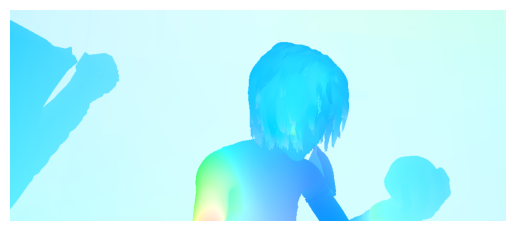

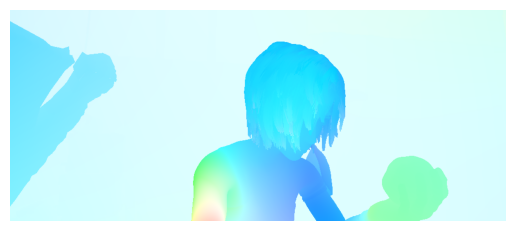

array([[[212, 247, 255],
        [212, 247, 255],
        [212, 247, 255],
        ...,
        [219, 255, 240],
        [219, 255, 240],
        [219, 255, 240]],

       [[212, 247, 255],
        [212, 247, 255],
        [212, 247, 255],
        ...,
        [219, 255, 240],
        [219, 255, 240],
        [219, 255, 240]],

       [[212, 247, 255],
        [212, 247, 255],
        [212, 247, 255],
        ...,
        [219, 255, 241],
        [219, 255, 241],
        [219, 255, 241]],

       ...,

       [[202, 254, 255],
        [202, 254, 255],
        [202, 254, 255],
        ...,
        [215, 252, 255],
        [215, 252, 255],
        [215, 252, 255]],

       [[202, 254, 255],
        [202, 254, 255],
        [202, 254, 255],
        ...,
        [215, 252, 255],
        [215, 252, 255],
        [215, 252, 255]],

       [[204, 254, 255],
        [202, 254, 255],
        [202, 254, 255],
        ...,
        [215, 252, 255],
        [215, 252, 255],
        [215, 252, 255]]

In [11]:
fileFlo1 = '/home/aistudio/EECS442_Ps10_OpticalFlow/MPI-Sintel-442/training/flow/alley_1/frame_0001.flo'
fileFlo2 = '/home/aistudio/EECS442_Ps10_OpticalFlow/MPI-Sintel-442/training/flow/alley_1/frame_0002.flo'
alley1_1Flow = readFlow(fileFlo1)
alley1_2Flow = readFlow(fileFlo2)
flo1 = alley1_1Flow
flo2 =alley1_2Flow

visualize_flow_array(flo1)
visualize_flow_array(flo2)


In [12]:
import torch
import torch.nn as nn
import math

def EPE(input_flow, target_flow):
    """
    Calculate the end point error between the input_flow and target_flow.
    """
    return torch.norm(target_flow - input_flow, p=2, dim=1).mean()

class L1(nn.Module):
    def __init__(self):
        super(L1, self).__init__()

    def forward(self, output, target):
        lossvalue = torch.abs(output - target).mean()
        return lossvalue

class L2(nn.Module):
    def __init__(self):
        super(L2, self).__init__()

    def forward(self, output, target):
        lossvalue = torch.norm(output - target, p=2, dim=1).mean()
        return lossvalue

class MultiScale(nn.Module):
    """
    PWC-Net outputs optical flow at multiple scales. Network is trained by
    minimizing a multi-scale regression loss between the predicted multi-scale
    flows and multi-scale groundtruth flows.
    """
    def __init__(self, startScale=4, numScales=5, l_weight=0.32, norm='L1'):
        super(MultiScale, self).__init__()

        self.startScale = startScale
        self.numScales = numScales
        self.loss_weights = torch.FloatTensor([(l_weight / 2 ** scale) for scale in range(self.numScales)]).cuda()
        self.l_type = norm
        self.div_flow = 0.05
        assert(len(self.loss_weights) == self.numScales)

        if self.l_type == 'L1':
            self.loss = L1()
        else:
            self.loss = L2()

        self.multiScales = [nn.AvgPool2d(self.startScale * (2**scale), self.startScale * (2**scale)) for scale in range(self.numScales)]
        self.loss_labels = ['MultiScale-' + self.l_type, 'EPE'],

    def forward(self, output, target):
        lossvalue = 0
        epevalue = 0

        if type(output) is tuple:
            target = self.div_flow * target
            for i, output_ in enumerate(output):
                # Total loss is the weighted average of losses at each scale.
                target_ = self.multiScales[i](target)
                epevalue += self.loss_weights[i] * EPE(output_, target_)
                lossvalue += self.loss_weights[i] * self.loss(output_, target_)
            return [lossvalue, epevalue]
        else:
            epevalue += EPE(output, target)
            lossvalue += self.loss(output, target)
            return [lossvalue, epevalue]